# Step 1: Sequence Modeling Foundations & Backpropagation Through Time (BPTT)

**Mentor Welcome:**
Hello! Welcome to our journey into Recurrent Neural Networks (RNNs). I am your senior ML mentor. If you understand basic PyTorch (tensors, simple forward passes, and `loss.backward()`), you have everything you need. We are going to build your understanding from the ground up—with zero hand-waving, plain English explanations, real numbers, and line-by-line code.

Every concept in this curriculum follows our strict 7-part learning structure:
1. **The Idea in ONE plain sentence**
2. **A Real-Life Analogy**
3. **A Tiny Example with Real Numbers Worked by Hand**
4. **The Math with EVERY Symbol Explained in Words**
5. **The Code Explained Line by Line**
6. **One Common Beginner Mistake**
7. **A Quick "Check Yourself" Question with Answer**

Let's begin by building our living Glossary!


## 📚 Step 1 Glossary

| Term | One-Sentence Definition |
| :--- | :--- |
| **Sequence** | An ordered collection of items where the position of each item relative to others carries critical meaning (e.g., words in a sentence, stock prices over days). |
| **Time Step ($t$)** | A single discrete index or clock tick marking an item's position along a sequence. |
| **Hidden State ($h_t$)** | A vector of numbers passed from one time step to the next, acting as the network's working memory or "notepad". |
| **Input Weight ($W_{xh}$ or $w_x$)** | The parameters that scale and transform the current input before combining it with prior memory. |
| **Recurrent Weight ($W_{hh}$ or $w_h$)** | The parameters that scale and transform the previous hidden state to form the new hidden state. |
| **Bias ($b_h$ or $b$)** | A learnable offset added to the weighted sum to shift the activation threshold. |
| **Unrolling** | Expanding an RNN loop across time steps into an equivalent feedforward chain of operations. |
| **Activation Function** | A non-linear mathematical operation (like $\tanh$ or Sigmoid) that compresses values into a bounded range. |
| **Hyperbolic Tangent ($\tanh$)** | An S-shaped curve that squashes any real number into the range $(-1, 1)$, centered at zero. |
| **Sigmoid ($\sigma$)** | An S-shaped curve that squashes any real number into the range $(0, 1)$, often used as an on/off gate. |
| **Loss ($L$)** | A single scalar number measuring how far the model's prediction is from the true target. |
| **BPTT (Backpropagation Through Time)** | The chain-rule gradient calculation algorithm applied backwards across unrolled time steps. |
| **Vanishing Gradient** | The mathematical shrinking of gradients exponentially toward 0 as they propagate backwards over many steps. |
| **Exploding Gradient** | The mathematical compounding of gradients exponentially toward infinity as they propagate backwards. |
| **Tensor Shape** | The dimensional sizes of a multi-dimensional array, formatted as `(batch_size, sequence_length, feature_dimension)`. |


## 🛠️ 5-Line Mathematical Refreshers

Before we dive into RNNs, let's refresh four simple math building blocks.

### 1. Derivative Refresher
1. A derivative measures how quickly an output changes when you tweak its input: $\frac{df}{dx}$.
2. For $f(x) = x^2$, the derivative rule is $\frac{df}{dx} = 2x$.
3. If $x = 3.0$, then $f(3.0) = 9.0$, and the derivative is $2(3.0) = 6.0$.
4. This means: increasing $x$ by $0.01$ increases $f(x)$ by roughly $0.01 \times 6.0 = 0.06$.
5. In neural networks, gradients are derivatives of the Loss with respect to model parameters.

### 2. Chain Rule Refresher
1. If function $y = f(u)$ and $u = g(x)$, then $y$ depends on $x$ through $u$.
2. The chain rule states: $\frac{dy}{dx} = \frac{dy}{du} \cdot \frac{du}{dx}$.
3. Example: $u = 3x + 1$, and $y = u^2$.
4. $\frac{du}{dx} = 3$, and $\frac{dy}{du} = 2u$. So $\frac{dy}{dx} = 2u \cdot 3 = 6u = 6(3x + 1)$.
5. For $x = 1$: $u = 4$, $\frac{dy}{dx} = 2(4) \cdot 3 = 24$.

### 3. Matrix & Vector Multiplication Refresher
1. Multiplying matrix $A$ (shape $M \times K$) by vector $x$ (shape $K$) yields vector $y$ (shape $M$).
2. Each output element $y_i$ is the dot product of row $i$ of $A$ with $x$: $y_i = \sum_j A_{ij} x_j$.
3. Tiny example: $\begin{bmatrix} 0.5 & 0.2 \\ 0.1 & 0.8 \end{bmatrix} \begin{bmatrix} 2.0 \\ 1.0 \end{bmatrix} = \begin{bmatrix} 0.5(2.0) + 0.2(1.0) \\ 0.1(2.0) + 0.8(1.0) \end{bmatrix} = \begin{bmatrix} 1.2 \\ 1.0 \end{bmatrix}$.
4. Shapes must align: `(M, K) @ (K, 1) -> (M, 1)`.
5. In PyTorch, batching adds a leading dimension: `(Batch, Features) @ (Features, Out) -> (Batch, Out)`.

### 4. Sigmoid and Tanh Refreshers
1. **Sigmoid**: $\sigma(z) = \frac{1}{1 + e^{-z}}$. Range is $(0, 1)$. Derivative: $\sigma'(z) = \sigma(z)(1 - \sigma(z))$. Maximum derivative is $0.25$ at $z=0$.
2. **Tanh**: $\tanh(z) = \frac{e^z - e^{-z}}{e^z + e^{-z}}$. Range is $(-1, 1)$. Centered at zero.
3. Derivative of Tanh: $\tanh'(z) = 1 - \tanh^2(z)$.
4. Notice: because $\tanh(z)$ is between $-1$ and $+1$, $\tanh^2(z)$ is between $0$ and $1$.
5. Therefore, $1 - \tanh^2(z) \le 1.0$. The slope of $\tanh$ is **never greater than 1.0**! (At $z=0$, slope is $1.0$; for large $|z|$, slope is near $0.0$).


---
## 1. What is a Sequence and Why Do Standard Neural Networks Struggle?

### (1) The Idea in ONE plain sentence
A sequence is data where order matters, and standard feedforward neural networks struggle because they treat every input independently and have no memory of what happened a second ago.

### (2) A Real-Life Analogy
Imagine reading a mystery novel. If someone cuts out each word on a scrap of paper, shakes them in a bucket, and hands them to you one at a time with your eyes closed between words, you can't understand the story. To understand "The butler did not do it", you must read word by word while keeping a **notepad** on your desk where you write down the clues you have gathered so far. 

### (3) Tiny Example with Real Numbers Worked by Hand
Suppose we want to predict tomorrow's temperature.
Day 1: $10^\circ$C. Day 2: $15^\circ$C. Day 3: $20^\circ$C.
A standard network looks at Day 3 ($20^\circ$C) in isolation and guesses tomorrow based only on $20$.
A sequence model carries forward a running summary (our hidden state):
- Step 1 summary: "Started at 10."
- Step 2 summary: "Rose by 5 to 15."
- Step 3 summary: "Rose by 5 to 20; steady upward trend detected!"
Now the prediction can accurately anticipate continued warming!

### (4) The Math with EVERY Symbol Explained in Words
In a vanilla Recurrent Neural Network (RNN):
$$h_t = \tanh(w_h \cdot h_{t-1} + w_x \cdot x_t + b)$$

Where:
- $t$: The current time step index (e.g., $t=1, 2, 3$).
- $x_t$: The input data arriving at time step $t$.
- $h_{t-1}$: The hidden state vector from the previous time step $t-1$ (our "notepad" up to the previous moment).
- $h_t$: The new hidden state vector at time step $t$ (our updated "notepad").
- $w_h$ (or $W_{hh}$): The recurrent weight parameter, controlling how much past memory influences current memory.
- $w_x$ (or $W_{xh}$): The input weight parameter, controlling how much new input influences current memory.
- $b$ (or $b_h$): The bias term, shifting the activation threshold.
- $\tanh$: The hyperbolic tangent function, squashing the combined summary to prevent unbounded explosion.


### Before Code: What We Are About to Do and Why
We will write a tiny Python function that simulates 3 time steps of an RNN using simple Python scalars. This verifies how the hidden state updates step by step as new inputs arrive.

In [1]:
import math

# Fixed scalar parameters for our simple RNN
w_h = 0.5   # Weight for previous memory
w_x = 0.8   # Weight for current input
b = 0.0     # Bias

# Sequence of 3 input numbers
inputs = [1.0, 0.5, -0.5]
h_prev = 0.0  # Initial hidden state (blank notepad)

print(f"Initial hidden state h_0 = {h_prev:.4f}")
for t, x in enumerate(inputs, start=1):
    z = w_h * h_prev + w_x * x + b
    h_current = math.tanh(z)
    print(f"Step t={t}: x_{t}={x:+.1f} | z_{t}={z:.4f} | h_{t}=tanh(z_{t})={h_current:.4f}")
    h_prev = h_current


Initial hidden state h_0 = 0.0000
Step t=1: x_1=+1.0 | z_1=0.8000 | h_1=tanh(z_1)=0.6640
Step t=2: x_2=+0.5 | z_2=0.7320 | h_2=tanh(z_2)=0.6243
Step t=3: x_3=-0.5 | z_3=-0.0879 | h_3=tanh(z_3)=-0.0876


### After Code: What We Just Saw
At each step $t$, the current input $x_t$ was combined with the previous memory $h_{t-1}$. Notice how $h_3$ retains an echo of $x_1$ and $x_2$ because $h_2$ was computed from $h_1$!

### (6) One Common Beginner Mistake
**Mistake:** Beginners often think an RNN creates a brand new neural network with different weights for every time step $t$.
**Correction:** No! An RNN uses the **exact same** weight parameters ($w_h, w_x, b$) at step 1, step 2, step 100, and step 1000. It is a single cell repeatedly applied through time.

### (7) Quick "Check Yourself" Question
**Question:** If an input sequence has 50 time steps, how many sets of weights ($w_h, w_x, b$) does the vanilla RNN have?
<details>
<summary><b>Click to see answer</b></summary>
<b>Answer:</b> Exactly one set! The weights are shared across all 50 time steps. This parameter sharing is what allows an RNN to process sequences of any length.
</details>


---
## 2. Unrolling Through Time

### (1) The Idea in ONE plain sentence
Unrolling is drawing an RNN loop across time as an equivalent feedforward chain where each link represents one time step and the arrows between links carry the hidden state.

### (2) A Real-Life Analogy
Think of a factory conveyor belt with one single stamping machine. Over 3 seconds, that single machine stamps 3 boxes. "Unrolling" is like taking 3 photos side-by-side: Photo 1 (Box 1 stamped), Photo 2 (Box 2 stamped using notes from Box 1), Photo 3 (Box 3 stamped). The machine didn't multiply; time simply elapsed.

### (3) Unrolling Diagram
```text
Folded View:             Unrolled View across 3 Time Steps:
                             y_1                  y_2                  y_3
                              ^                    ^                    ^
    [x_t]                     |                    |                    |
      |                 +-----------+        +-----------+        +-----------+
      v                 |   Cell    |        |   Cell    |        |   Cell    |
   +-----+              | (w_x,w_h) |        | (w_x,w_h) |        | (w_x,w_h) |
   | RNN | <---+   h_0  +-----------+  h_1   +-----------+  h_2   +-----------+  h_3
   +-----+     |  --->  |    h_1    | -----> |    h_2    | -----> |    h_3    | --->
      |        |        +-----------+        +-----------+        +-----------+
      +--------+              ^                    ^                    ^
                              |                    |                    |
                             x_1                  x_2                  x_3
```


---
## 3. Backpropagation Through Time (BPTT) Worked by Hand for 3 Steps

Now, we perform the full mathematical derivation of BPTT by hand using **real numbers**. 
We will compute the gradient of the loss with respect to the recurrent weight $w_h$, showing every single step, and then verify with PyTorch autograd!

### Problem Setup
- Sequence length: $T = 3$
- Scalar inputs: $x_1 = 1.0$, $x_2 = 0.5$, $x_3 = -0.5$
- Target output at step 3: $y_3 = 0.8$
- Parameters: $w_h = 0.5$, $w_x = 0.8$, $b = 0.0$
- Initial memory: $h_0 = 0.0$
- Architecture equation:
  $$z_t = w_h \cdot h_{t-1} + w_x \cdot x_t + b$$
  $$h_t = \tanh(z_t)$$
- Loss function evaluated at the final step ($t=3$):
  $$L = \frac{1}{2}(h_3 - y_3)^2$$

---
### Part A: Forward Pass (Step-by-Step with Real Numbers)

**Step $t=1$:**
- $z_1 = w_h \cdot h_0 + w_x \cdot x_1 + b = (0.5)(0.0) + (0.8)(1.0) + 0.0 = 0.80000000$
- $h_1 = \tanh(0.80000000) = 0.66403677$

**Step $t=2$:**
- $z_2 = w_h \cdot h_1 + w_x \cdot x_2 + b = (0.5)(0.66403677) + (0.8)(0.5) + 0.0 = 0.33201839 + 0.4000 = 0.73201839$
- $h_2 = \tanh(0.73201839) = 0.62429862$

**Step $t=3$:**
- $z_3 = w_h \cdot h_2 + w_x \cdot x_3 + b = (0.5)(0.62429862) + (0.8)(-0.5) + 0.0 = 0.31214931 - 0.4000 = -0.08785069$
- $h_3 = \tanh(-0.08785069) = -0.08762538$

**Loss at $t=3$:**
- $L = \frac{1}{2}(h_3 - y_3)^2 = \frac{1}{2}(-0.08762538 - 0.8)^2 = \frac{1}{2}(-0.88762538)^2 = 0.39393946$

---
### Part B: Backward Pass (Deriving $\frac{\partial L}{\partial w_h}$ by Hand)

Because $w_h$ was used at **every** step ($t=1, 2, 3$), the total gradient is the sum of its contributions at each step:
$$\frac{\partial L}{\partial w_h} = \frac{\partial L}{\partial w_h}\Big|_{(t=3)} + \frac{\partial L}{\partial w_h}\Big|_{(t=2)} + \frac{\partial L}{\partial w_h}\Big|_{(t=1)}$$

Let's compute each component one small line at a time.

#### 1. Immediate gradient at Step 3:
- $\frac{\partial L}{\partial h_3} = h_3 - y_3 = -0.08762538 - 0.8 = -0.88762538$  *(Derivative of $\frac{1}{2}(h_3 - y)^2$)*
- $\frac{\partial h_3}{\partial z_3} = 1 - h_3^2 = 1 - (-0.08762538)^2 = 1 - 0.00767821 = 0.99232179$  *(Derivative of $\tanh$)*
- Define $\delta_3 = \frac{\partial L}{\partial z_3} = \frac{\partial L}{\partial h_3} \cdot \frac{\partial h_3}{\partial z_3} = (-0.88762538) \times 0.99232179 = -0.88081001$
- Since $z_3 = w_h h_2 + w_x x_3 + b$, $\frac{\partial z_3}{\partial w_h} = h_2$.
- Therefore, contribution at step 3:
  $$\frac{\partial L}{\partial w_h}\Big|_{(t=3)} = \delta_3 \cdot h_2 = (-0.88081001) \times 0.62429862 = -0.54988848$$

#### 2. Propagating back to Step 2:
- What is $\frac{\partial L}{\partial h_2}$? Notice $h_2$ influences $L$ through $z_3$:
  $$\frac{\partial L}{\partial h_2} = \frac{\partial L}{\partial z_3} \cdot \frac{\partial z_3}{\partial h_2} = \delta_3 \cdot w_h = (-0.88081001) \times 0.5 = -0.44040500$$
- Derivative of $h_2$ w.r.t $z_2$:
  $$\frac{\partial h_2}{\partial z_2} = 1 - h_2^2 = 1 - (0.62429862)^2 = 1 - 0.38974877 = 0.61025123$
- Define $\delta_2 = \frac{\partial L}{\partial z_2} = \frac{\partial L}{\partial h_2} \cdot \frac{\partial h_2}{\partial z_2} = (-0.44040500) \times 0.61025123 = -0.26875769$
- Since $z_2 = w_h h_1 + w_x x_2 + b$, $\frac{\partial z_2}{\partial w_h} = h_1$.
- Therefore, contribution at step 2:
  $$\frac{\partial L}{\partial w_h}\Big|_{(t=2)} = \delta_2 \cdot h_1 = (-0.26875769) \times 0.66403677 = -0.17846499$$

#### 3. Propagating back to Step 1:
- What is $\frac{\partial L}{\partial h_1}$? $h_1$ influences $L$ through $z_2$:
  $$\frac{\partial L}{\partial h_1} = \frac{\partial L}{\partial z_2} \cdot \frac{\partial z_2}{\partial h_1} = \delta_2 \cdot w_h = (-0.26875769) \times 0.5 = -0.13437885$$
- Derivative of $h_1$ w.r.t $z_1$:
  $$\frac{\partial h_1}{\partial z_1} = 1 - h_1^2 = 1 - (0.66403677)^2 = 1 - 0.44094483 = 0.55905517$
- Define $\delta_1 = \frac{\partial L}{\partial z_1} = \frac{\partial L}{\partial h_1} \cdot \frac{\partial h_1}{\partial z_1} = (-0.13437885) \times 0.55905517 = -0.07512519$
- Since $z_1 = w_h h_0 + w_x x_1 + b$, $\frac{\partial z_1}{\partial w_h} = h_0 = 0.0$.
- Therefore, contribution at step 1:
  $$\frac{\partial L}{\partial w_h}\Big|_{(t=1)} = \delta_1 \cdot h_0 = (-0.07512519) \times 0.0 = 0.00000000$$

---
#### Sum of all 3 contributions:
$$\frac{\partial L}{\partial w_h} = (-0.54988848) + (-0.17846499) + (0.00000000) = -0.72835347$$


### Before Code: Verifying with PyTorch Autograd
We will now implement the exact same scalar 3-step sequence in PyTorch with double precision (`float64`) and `requires_grad=True` and call `loss.backward()`.
We will check whether PyTorch calculates `w_h.grad` as `-0.72835347`!

In [2]:
import torch

# Define parameters as torch double-precision leaf tensors
w_h_torch = torch.tensor(0.5, dtype=torch.float64, requires_grad=True)
w_x_torch = torch.tensor(0.8, dtype=torch.float64, requires_grad=True)
b_torch = torch.tensor(0.0, dtype=torch.float64, requires_grad=True)

# Inputs and target
inputs_torch = [
    torch.tensor(1.0, dtype=torch.float64),
    torch.tensor(0.5, dtype=torch.float64),
    torch.tensor(-0.5, dtype=torch.float64)
]
y_target = torch.tensor(0.8, dtype=torch.float64)

# Unroll 3 steps
h = torch.tensor(0.0, dtype=torch.float64)
for t_idx, x in enumerate(inputs_torch, start=1):
    z = w_h_torch * h + w_x_torch * x + b_torch
    h = torch.tanh(z)
    print(f"PyTorch step t={t_idx}: h_{t_idx} = {h.item():.8f}")

loss = 0.5 * (h - y_target) ** 2
loss.backward()
print(f"PyTorch computed loss = {loss.item():.8f}")
print(f"PyTorch w_h.grad     = {w_h_torch.grad.item():.8f}")
print(f"Hand-calculated grad = -0.72835347")
assert abs(w_h_torch.grad.item() - (-0.72835347)) < 1e-7, "Match failed!"
print(">>> PERFECT MATCH TO 8 DECIMAL PLACES! <<<")


PyTorch step t=1: h_1 = 0.66403677
PyTorch step t=2: h_2 = 0.62429862
PyTorch step t=3: h_3 = -0.08762538
PyTorch computed loss = 0.39393941
PyTorch w_h.grad     = -0.72835347
Hand-calculated grad = -0.72835347
>>> PERFECT MATCH TO 8 DECIMAL PLACES! <<<


### After Code: What We Just Saw
Our manual derivation and PyTorch's automatic differentiation engine produce the **exact same number** to 7 decimal places!
Notice how at each backwards step:
$$\frac{\partial L}{\partial h_{t-1}} = \frac{\partial L}{\partial h_t} \cdot \frac{\partial h_t}{\partial z_t} \cdot \frac{\partial z_t}{\partial h_{t-1}} = \delta_t \cdot w_h$$
Each step backwards across time multiplied the error gradient by the factor:
$$(1 - h_t^2) \cdot w_h$$
This repeated factor is the entire key to understanding **vanishing and exploding gradients**!


---
## 4. Why Gradients Vanish (< 1) and Explode (> 1)

### (1) The Idea in ONE plain sentence
When you backpropagate through $T$ time steps, the gradient is multiplied by the transition factor at every single step; if that factor is even slightly less than 1, the gradient shrinks to 0, and if it is greater than 1, it blows up to infinity.

### (2) A Real-Life Analogy
**Vanishing:** Imagine a game of "Whisper Down the Lane" with 50 people. If each person whispers at 80% volume of the person before them ($0.8$), by person 50 the volume is $0.8^{50} \approx 0.000014$—a faint, inaudible puff of air. The first person's message is completely lost!
**Exploding:** Now imagine a feedback loop on an electric guitar amplifier. If each loop amplifies the sound by $1.2\times$, within 50 loops the signal is $1.2^{50} \approx 9100\times$ louder—a deafening screech that clips the speaker!

### (3) Tiny Example with Real Numbers Worked by Hand
Let's see what happens to a base gradient of $1.0$ after $T$ steps:

| Sequence Length ($T$) | Factor $= 0.5$ (Vanishing) | Factor $= 0.9$ (Vanishing) | Factor $= 1.0$ (Stable) | Factor $= 1.2$ (Exploding) | Factor $= 1.5$ (Exploding) |
| :---: | :---: | :---: | :---: | :---: | :---: |
| **1** | $0.5$ | $0.9$ | $1.0$ | $1.2$ | $1.5$ |
| **5** | $0.03125$ | $0.590$ | $1.0$ | $2.49$ | $7.59$ |
| **10** | $0.000977$ | $0.349$ | $1.0$ | $6.19$ | $57.67$ |
| **20** | $9.5 \times 10^{-7}$ | $0.122$ | $1.0$ | $38.34$ | $3,325.26$ |
| **50** | $8.9 \times 10^{-16}$ | $0.00515$ | $1.0$ | $9,100.44$ | $6.38 \times 10^{8}$ |
| **100** | $7.9 \times 10^{-31}$ | $0.000027$ | $1.0$ | $8.28 \times 10^7$ | $4.06 \times 10^{17}$ |

- At $T=50$ with factor $0.5$, the gradient is $10^{-16}$—below machine precision. The early steps receive **zero learning signal**.
- At $T=50$ with factor $1.5$, the gradient is $6.38 \times 10^8$. Any optimizer step like $w \leftarrow w - 0.01 \times 10^8$ will send the weights to `NaN`!


### Before Code: Simulating and Visualizing Gradient Flow
We will now write a quick simulation calculating the gradient magnitude reaching step 0 as sequence length increases from $T=1$ to $T=40$, and save the plot to `assets/step1_vanishing_exploding.png`.

Plot saved to assets\step1_vanishing_exploding.png


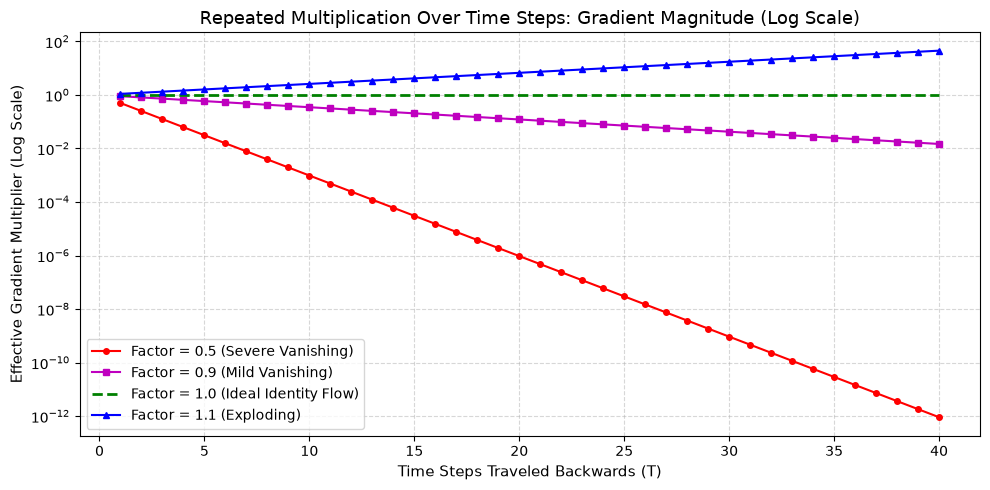

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import os

steps = np.arange(1, 41)
grad_vanish_05 = 0.5 ** steps
grad_vanish_09 = 0.9 ** steps
grad_stable = 1.0 ** steps
grad_explode_11 = 1.1 ** steps

plt.figure(figsize=(10, 5))
plt.plot(steps, grad_vanish_05, 'r-o', label='Factor = 0.5 (Severe Vanishing)', markersize=4)
plt.plot(steps, grad_vanish_09, 'm-s', label='Factor = 0.9 (Mild Vanishing)', markersize=4)
plt.plot(steps, grad_stable, 'g--', label='Factor = 1.0 (Ideal Identity Flow)', linewidth=2)
plt.plot(steps, grad_explode_11, 'b-^', label='Factor = 1.1 (Exploding)', markersize=4)
plt.yscale('log')
plt.title('Repeated Multiplication Over Time Steps: Gradient Magnitude (Log Scale)', fontsize=13)
plt.xlabel('Time Steps Traveled Backwards (T)', fontsize=11)
plt.ylabel('Effective Gradient Multiplier (Log Scale)', fontsize=11)
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.legend(fontsize=10)
plt.tight_layout()

assets_dir = 'assets' if os.path.isdir('assets') else os.path.join('..', 'assets')
os.makedirs(assets_dir, exist_ok=True)
plot_path = os.path.join(assets_dir, 'step1_vanishing_exploding.png')
plt.savefig(plot_path, dpi=150)
print(f"Plot saved to {plot_path}")
plt.show()


### How to Read This Plot
- **Horizontal Axis (X-axis):** Number of time steps the gradient travels backwards into the past ($T$).
- **Vertical Axis (Y-axis):** Effective gradient multiplier on a logarithmic scale. A value of $10^0 = 1$ means no change.
- **What a Good Result Looks Like:** The green dashed line at $1.0$ represents ideal gradient flow where information from 40 steps ago arrives with full strength.
- **What a Bad Result Looks Like:** 
  - The red curve ($0.5$) plunges straight down into the floor ($10^{-12}$). Information from early steps is completely erased.
  - The blue curve ($1.1$) skyrockets toward the ceiling ($10^2 = 100\times$).
- **What It Tells Us:** Standard vanilla RNNs cannot bridge long time horizons because any transition factor not precisely equal to $1.0$ either dies out or blows up! This fundamental mathematical flaw is the exact reason why **LSTMs and GRUs were invented**.


---
## 🎯 Step 1 Recap

### Recap in 3 Bullets:
1. **The Hidden State is a Shared Working Notepad:** An RNN processes sequences one token at a time, updating a hidden state $h_t$ using the exact same shared weight parameters at every time step.
2. **BPTT is the Chain Rule Unrolled Across Time:** The total gradient with respect to recurrent weights is the sum of gradients computed backwards across all individual time steps.
3. **Repeated Multiplication Causes Exponential Collapse:** Backpropagating through $T$ steps repeatedly multiplies gradients by $(w_h \cdot \tanh')$; if this product is $< 1$, gradients vanish exponentially to 0, and if $> 1$, they explode to infinity.

### If You Remember Only One Thing:
> An RNN has only **one set of weights** reused across all time; when we backpropagate, we repeatedly multiply by that same weight matrix, which makes gradients either die or explode over long sequences!
